# Llama 3.2 3B – Time & Space Complexity at Q4_0

This notebook:
1. Loads the base Llama 3.2 3B model via Unsloth and exports it as a **Q4_0 GGUF** file
2. Loads that GGUF with **llama-cpp-python** — the same runtime llama.cpp/Ollama uses
3. Measures **space complexity** (file size, RAM usage, KV cache)
4. Measures **time complexity** (prefill latency, decode throughput) across sequence lengths

**Q4_0** stores every weight in exactly 4 bits (no mixed precision), making it the
simplest and most aggressive standard GGUF quantization:
`memory ≈ total_params × 0.5 bytes`

### Installation

In [1]:
%%capture
import os, re
if "COLAB_" not in "".join(os.environ.keys()):
    !pip install unsloth
else:
    import torch; v = re.match(r"[0-9]{1,}\.[0-9]{1,}", str(torch.__version__)).group(0)
    xformers = "xformers==" + ("0.0.33.post1" if v=="2.9" else "0.0.32.post2" if v=="2.8" else "0.0.29.post3")
    !pip install --no-deps bitsandbytes accelerate {xformers} peft trl triton cut_cross_entropy unsloth_zoo
    !pip install sentencepiece protobuf "datasets==4.3.0" "huggingface_hub>=0.34.0" hf_transfer
    !pip install --no-deps unsloth
!pip install transformers==4.56.2
!pip install --no-deps trl==0.22.2

In [2]:
# Install llama-cpp-python.
# On Colab T4 we build with CUDA support for accurate GPU benchmarks.
import subprocess, sys

try:
    import torch
    has_cuda = torch.cuda.is_available()
except ImportError:
    has_cuda = False

if has_cuda:
    print("CUDA detected – installing llama-cpp-python with CUDA support...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        "llama-cpp-python",
        "--extra-index-url", "https://abetlen.github.io/llama-cpp-python/whl/cu121",
        "--quiet",
    ])
else:
    print("No CUDA – installing CPU-only llama-cpp-python...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "llama-cpp-python", "--quiet"])

print("llama-cpp-python installed.")

CUDA detected – installing llama-cpp-python with CUDA support...
llama-cpp-python installed.


### Load Model – Download Pre-Built Q4_0 GGUF

In [3]:
# Download the pre-built Q4_0 GGUF directly from HuggingFace.
# This avoids the Unsloth GGUF conversion step, which requires full-precision
# weights and OOMs on a T4 GPU.
# bartowski's repo is the standard community source for quantized GGUFs.

from huggingface_hub import hf_hub_download
import os

REPO_ID   = "bartowski/Llama-3.2-3B-Instruct-GGUF"
FILENAME  = "Llama-3.2-3B-Instruct-Q4_0.gguf"

print(f"Downloading {FILENAME} from {REPO_ID} ...")
GGUF_PATH = hf_hub_download(repo_id=REPO_ID, filename=FILENAME)
print(f"Downloaded → {GGUF_PATH}")
print(f"File size  → {os.path.getsize(GGUF_PATH)/1024**3:.3f} GB")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Llama-3.2-3B-Instruct-Q4_0.gguf:   0%|          | 0.00/1.92G [00:00<?, ?B/s]

Downloaded → /root/.cache/huggingface/hub/models--bartowski--Llama-3.2-3B-Instruct-GGUF/snapshots/5ab33fa94d1d04e903623ae72c95d1696f09f9e8/Llama-3.2-3B-Instruct-Q4_0.gguf
File size  → 1.790 GB


---
## Step 2: Space Complexity at Q4_0

### 2a. File Size & Theoretical Footprint

In [4]:
import os

file_bytes = os.path.getsize(GGUF_PATH)
file_gb    = file_bytes / 1024**3

# Q4_0: each weight block = 32 weights × 4 bits + 1 fp16 scale = 18 bytes/block
# Effective bits per weight ≈ (32×4 + 16) / 32 = 4.5 bits
# For a quick estimate we use 4.5 bpw.
TOTAL_PARAMS = 3_212_749_824   # Llama 3.2 3B exact param count

print("=" * 55)
print("  Q4_0 GGUF File – Space Complexity")
print("=" * 55)
print(f"  GGUF file size:          {file_bytes:>14,} bytes")
print(f"                           {file_gb:>14.3f} GB")
print()
print("  Theoretical footprint by precision:")
for label, bpp in [
    ("float32  (4.00 B/param)", 4.0),
    ("float16  (2.00 B/param)", 2.0),
    ("int8     (1.00 B/param)", 1.0),
    ("Q4_K_M   (0.5625 B/param – mixed)", 4.5/8),
    ("Q4_0     (0.5625 B/param – uniform)", 4.5/8),
    ("Q4_0 raw (0.500 B/param – 4 bit only)", 0.5),
]:
    size_gb = TOTAL_PARAMS * bpp / 1024**3
    print(f"  {label}: {size_gb:.3f} GB")

print()
print(f"  Compression vs fp32:  {TOTAL_PARAMS*4/file_bytes:.1f}× smaller")
print("=" * 55)

  Q4_0 GGUF File – Space Complexity
  GGUF file size:           1,921,909,280 bytes
                                    1.790 GB

  Theoretical footprint by precision:
  float32  (4.00 B/param): 11.968 GB
  float16  (2.00 B/param): 5.984 GB
  int8     (1.00 B/param): 2.992 GB
  Q4_K_M   (0.5625 B/param – mixed): 1.683 GB
  Q4_0     (0.5625 B/param – uniform): 1.683 GB
  Q4_0 raw (0.500 B/param – 4 bit only): 1.496 GB

  Compression vs fp32:  6.7× smaller


### 2b. Load GGUF & Measure Runtime Memory

In [5]:
import psutil, os
from llama_cpp import Llama

process = psutil.Process(os.getpid())

mem_before = process.memory_info().rss  # resident set size

# n_gpu_layers=-1 offloads all layers to GPU if CUDA is available.
# Set to 0 to force CPU-only.
llm = Llama(
    model_path   = GGUF_PATH,
    n_ctx        = 2048,      # context window
    n_batch      = 512,       # batch size for prompt processing
    n_gpu_layers = -1,        # offload all layers to GPU
    verbose      = False,
)

mem_after = process.memory_info().rss
ram_used_gb = (mem_after - mem_before) / 1024**3

print("=" * 55)
print("  Runtime Memory (llama-cpp-python)")
print("=" * 55)
print(f"  RAM used after load: {ram_used_gb:.3f} GB")
print(f"  GGUF file on disk:   {file_gb:.3f} GB")
print()
# llama.cpp context buffer (KV cache + scratch) adds overhead on top of weights
ctx = llm.context_params
print(f"  Context window:      {llm.n_ctx()} tokens")
print(f"  Threads:             {llm.n_threads}")
print("=" * 55)

llama_context: n_ctx_seq (2048) < n_ctx_train (131072) -- the full capacity of the model will not be utilized


  Runtime Memory (llama-cpp-python)
  RAM used after load: 3.503 GB
  GGUF file on disk:   1.790 GB

  Context window:      2048 tokens
  Threads:             1


### 2c. KV Cache Size at Q4_0 Runtime

In [6]:
# llama.cpp stores KV cache in fp16 by default.
# KV cache = 2 (K+V) × L × seq_len × n_kv_heads × head_dim × 2 bytes
L        = 28    # Llama 3.2 3B layers
kv_heads = 8     # GQA key-value heads
head_dim = 128   # 3072 hidden / 24 attn heads

print(f"{'Seq len':>10} | {'KV cache MB':>12} | {'Total w/ model GB':>18}")
print("-" * 48)
for seq in [128, 256, 512, 1024, 2048, 4096]:
    kv_mb = 2 * L * seq * kv_heads * head_dim * 2 / 1024**2
    total_gb = file_gb + kv_mb / 1024
    print(f"{seq:>10,} | {kv_mb:>12.2f} | {total_gb:>18.3f}")

   Seq len |  KV cache MB |  Total w/ model GB
------------------------------------------------
       128 |        14.00 |              1.804
       256 |        28.00 |              1.817
       512 |        56.00 |              1.845
     1,024 |       112.00 |              1.899
     2,048 |       224.00 |              2.009
     4,096 |       448.00 |              2.227


---
## Step 3: Time Complexity at Q4_0

llama.cpp processes prompts in chunks (prefill) then decodes token-by-token.
We measure both phases using the same runtime the GGUF would run in production.

### 3a. Prefill Latency vs Sequence Length

In [7]:
import time, random, string

def random_prompt(n_tokens):
    """Generate a dummy prompt that tokenizes to approximately n_tokens."""
    # ~4 chars per token is a rough average for Llama tokenizer
    chars = string.ascii_letters + " "
    return "".join(random.choice(chars) for _ in range(n_tokens * 4))

def benchmark_prefill_gguf(llm, n_tokens, n_runs=3):
    prompt = random_prompt(n_tokens)
    # Warm-up
    _ = llm(prompt, max_tokens=1, echo=False)

    latencies = []
    for _ in range(n_runs):
        t0 = time.perf_counter()
        out = llm(prompt, max_tokens=1, echo=False)
        latencies.append(time.perf_counter() - t0)

    # llama.cpp reports exact token count used
    used_tokens = out["usage"]["prompt_tokens"]
    mean_s = sum(latencies) / len(latencies)
    return {
        "requested_tokens": n_tokens,
        "actual_tokens":    used_tokens,
        "mean_ms":          round(mean_s * 1000, 2),
        "min_ms":           round(min(latencies) * 1000, 2),
        "tokens_per_sec":   round(used_tokens / mean_s),
    }

prefill_results = []
print(f"{'Req toks':>9} | {'Act toks':>9} | {'Mean ms':>9} | {'Tok/s':>8}")
print("-" * 46)
for n in [32, 64, 128, 256, 512, 1024, 1800]:
    try:
        r = benchmark_prefill_gguf(llm, n)
        prefill_results.append(r)
        print(f"{r['requested_tokens']:>9} | {r['actual_tokens']:>9} | "
              f"{r['mean_ms']:>9.2f} | {r['tokens_per_sec']:>8,}")
    except Exception as e:
        print(f"{n:>9} | ERROR: {e}")
        break

 Req toks |  Act toks |   Mean ms |    Tok/s
----------------------------------------------
       32 |        81 |    354.59 |      228
       64 |       172 |    285.89 |      602
      128 |       333 |    293.88 |    1,133
      256 |       656 |    304.27 |    2,156
      512 |      1347 |    334.58 |    4,026
     1024 | ERROR: Requested tokens (2665) exceed context window of 2048


### 3b. Autoregressive Decode Throughput

In [8]:
def benchmark_decode_gguf(llm, prompt_tokens, new_tokens, n_runs=3):
    prompt = random_prompt(prompt_tokens)
    # Warm-up
    _ = llm(prompt, max_tokens=8)

    latencies = []
    for _ in range(n_runs):
        t0 = time.perf_counter()
        out = llm(prompt, max_tokens=new_tokens, echo=False)
        latencies.append(time.perf_counter() - t0)

    gen = out["usage"]["completion_tokens"]
    mean_s = sum(latencies) / len(latencies)
    return {
        "prompt_tokens": prompt_tokens,
        "new_tokens":    gen,
        "mean_s":        round(mean_s, 3),
        "ms_per_token":  round(mean_s / gen * 1000, 2) if gen else 0,
        "tokens_per_sec": round(gen / mean_s, 1) if gen else 0,
    }

decode_results = []
print(f"{'Prompt':>8} | {'New toks':>9} | {'ms/token':>9} | {'tok/s':>8}")
print("-" * 44)
for p, n in [(32, 64), (64, 128), (128, 128), (256, 64), (512, 32)]:
    try:
        r = benchmark_decode_gguf(llm, p, n)
        decode_results.append(r)
        print(f"{r['prompt_tokens']:>8} | {r['new_tokens']:>9} | "
              f"{r['ms_per_token']:>9.2f} | {r['tokens_per_sec']:>8.1f}")
    except Exception as e:
        print(f"{p:>8} | ERROR: {e}")

  Prompt |  New toks |  ms/token |    tok/s
--------------------------------------------
      32 |        64 |    294.91 |      3.4
      64 |       128 |    299.81 |      3.3
     128 |       128 |    311.06 |      3.2
     256 |        64 |    310.03 |      3.2
     512 |        32 |    330.84 |      3.0


### 3c. Theoretical FLOPs per Prefill (Q4_0)

In [9]:
# Q4_0 dequantises weights to fp16 before matmul, so FLOPs are the same as fp16.
# Standard estimate: FLOPs ≈ 2 × num_params × seq_len
print(f"{'Seq len':>10} | {'FLOPs':>20} | {'TFLOPs':>10}")
print("-" * 46)
for seq in [128, 256, 512, 1024, 2048]:
    flops = 2 * TOTAL_PARAMS * seq
    print(f"{seq:>10,} | {flops:>20,.0f} | {flops/1e12:>10.2f}")

print()
print("Note: Q4_0 dequantises to fp16 before compute,")
print("so arithmetic FLOPs match a fp16 model.")
print("Effective throughput is higher because memory bandwidth")
print("is reduced 4× vs fp32 (smaller model → faster load from RAM/VRAM).")

   Seq len |                FLOPs |     TFLOPs
----------------------------------------------
       128 |      822,463,954,944 |       0.82
       256 |    1,644,927,909,888 |       1.64
       512 |    3,289,855,819,776 |       3.29
     1,024 |    6,579,711,639,552 |       6.58
     2,048 |   13,159,423,279,104 |      13.16

Note: Q4_0 dequantises to fp16 before compute,
so arithmetic FLOPs match a fp16 model.
Effective throughput is higher because memory bandwidth
is reduced 4× vs fp32 (smaller model → faster load from RAM/VRAM).


### 3d. Save Benchmark Data to Disk

In [10]:
import json, csv, os
from datetime import datetime

run_ts = datetime.now().strftime("%Y%m%d_%H%M%S")
out_dir = "complexity_results"
os.makedirs(out_dir, exist_ok=True)

# ── Collate all results ──────────────────────────────────────────────────────
results = {
    "run_timestamp": run_ts,
    "model": "Llama-3.2-3B",
    "quantization": "Q4_0",
    "gguf_path": GGUF_PATH,
    "space": {
        "total_params":       TOTAL_PARAMS,
        "gguf_file_size_gb":  round(file_gb, 4),
        "ram_used_gb":        round(ram_used_gb, 4),
        "compression_vs_fp32": round(TOTAL_PARAMS * 4 / file_bytes, 2),
    },
    "kv_cache": [
        {"seq_len": s,
         "kv_cache_mb": round(2 * 28 * s * 8 * 128 * 2 / 1024**2, 3)}
        for s in [128, 256, 512, 1024, 2048, 4096]
    ],
    "prefill": prefill_results,
    "decode":  decode_results,
}

# ── Save JSON ────────────────────────────────────────────────────────────────
json_path = os.path.join(out_dir, f"results_{run_ts}.json")
with open(json_path, "w") as f:
    json.dump(results, f, indent=2)
print(f"JSON saved  → {json_path}")

# ── Save prefill CSV ─────────────────────────────────────────────────────────
prefill_csv = os.path.join(out_dir, f"prefill_{run_ts}.csv")
if prefill_results:
    with open(prefill_csv, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=prefill_results[0].keys())
        writer.writeheader()
        writer.writerows(prefill_results)
    print(f"Prefill CSV → {prefill_csv}")

# ── Save decode CSV ──────────────────────────────────────────────────────────
decode_csv = os.path.join(out_dir, f"decode_{run_ts}.csv")
if decode_results:
    with open(decode_csv, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=decode_results[0].keys())
        writer.writeheader()
        writer.writerows(decode_results)
    print(f"Decode CSV  → {decode_csv}")

# ── Save space summary CSV ───────────────────────────────────────────────────
space_csv = os.path.join(out_dir, f"space_{run_ts}.csv")
space_rows = [
    {"precision": "float32",  "bpp": 4.0,    "size_gb": round(TOTAL_PARAMS*4.0/1024**3, 3)},
    {"precision": "float16",  "bpp": 2.0,    "size_gb": round(TOTAL_PARAMS*2.0/1024**3, 3)},
    {"precision": "int8",     "bpp": 1.0,    "size_gb": round(TOTAL_PARAMS*1.0/1024**3, 3)},
    {"precision": "Q4_0",     "bpp": 0.5625, "size_gb": round(TOTAL_PARAMS*0.5625/1024**3, 3)},
    {"precision": "Q4_0_file","bpp": round(file_bytes/TOTAL_PARAMS*8, 3), "size_gb": round(file_gb, 3)},
]
with open(space_csv, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["precision","bpp","size_gb"])
    writer.writeheader()
    writer.writerows(space_rows)
print(f"Space CSV   → {space_csv}")

print(f"\nAll results saved to ./{out_dir}/")

JSON saved  → complexity_results/results_20260323_224452.json
Prefill CSV → complexity_results/prefill_20260323_224452.csv
Decode CSV  → complexity_results/decode_20260323_224452.csv
Space CSV   → complexity_results/space_20260323_224452.csv

All results saved to ./complexity_results/


### 3e. Visualise Results

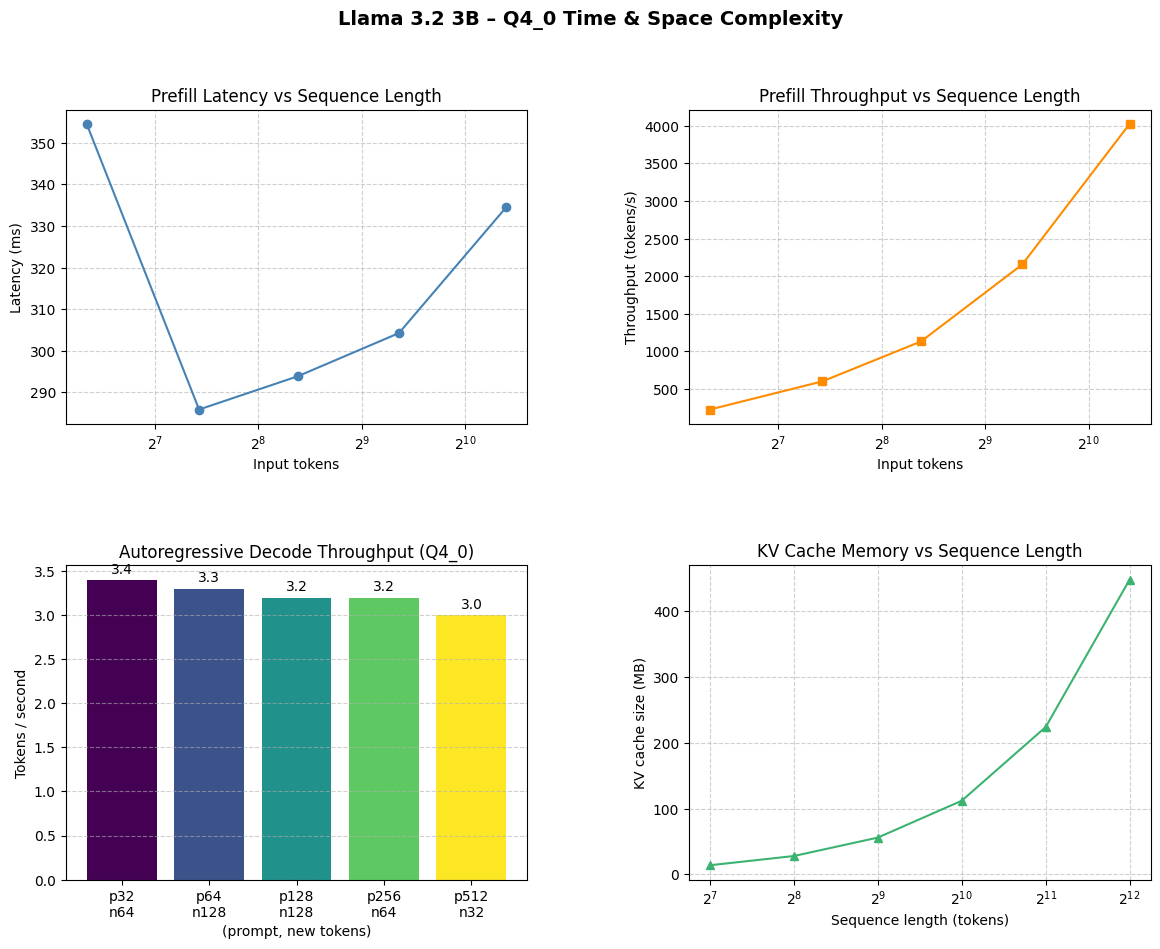

Figure saved as q4_0_complexity_20260323_224452.png


In [11]:
from datetime import datetime
run_ts = datetime.now().strftime("%Y%m%d_%H%M%S")
fig_path = f"q4_0_complexity_{run_ts}.png"

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(14, 10))
gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.35)

# Plot 1: Prefill latency
ax1 = fig.add_subplot(gs[0, 0])
if prefill_results:
    xs = [r["actual_tokens"] for r in prefill_results]
    ys = [r["mean_ms"]       for r in prefill_results]
    ax1.plot(xs, ys, marker="o", color="steelblue")
    ax1.set_xlabel("Input tokens")
    ax1.set_ylabel("Latency (ms)")
    ax1.set_title("Prefill Latency vs Sequence Length")
    ax1.set_xscale("log", base=2)
    ax1.grid(True, linestyle="--", alpha=0.6)

# Plot 2: Prefill throughput
ax2 = fig.add_subplot(gs[0, 1])
if prefill_results:
    ys2 = [r["tokens_per_sec"] for r in prefill_results]
    ax2.plot(xs, ys2, marker="s", color="darkorange")
    ax2.set_xlabel("Input tokens")
    ax2.set_ylabel("Throughput (tokens/s)")
    ax2.set_title("Prefill Throughput vs Sequence Length")
    ax2.set_xscale("log", base=2)
    ax2.grid(True, linestyle="--", alpha=0.6)

# Plot 3: Decode throughput
ax3 = fig.add_subplot(gs[1, 0])
if decode_results:
    labels = [f"p{r['prompt_tokens']}\nn{r['new_tokens']}" for r in decode_results]
    vals   = [r["tokens_per_sec"] for r in decode_results]
    colors = plt.cm.viridis([i / max(len(vals)-1,1) for i in range(len(vals))])
    bars   = ax3.bar(labels, vals, color=colors)
    ax3.set_xlabel("(prompt, new tokens)")
    ax3.set_ylabel("Tokens / second")
    ax3.set_title("Autoregressive Decode Throughput (Q4_0)")
    ax3.bar_label(bars, fmt="%.1f", padding=3)
    ax3.grid(axis="y", linestyle="--", alpha=0.6)

# Plot 4: KV cache vs seq len
ax4 = fig.add_subplot(gs[1, 1])
kv_seq = [128, 256, 512, 1024, 2048, 4096]
kv_mb  = [2 * L * s * kv_heads * head_dim * 2 / 1024**2 for s in kv_seq]
ax4.plot(kv_seq, kv_mb, marker="^", color="mediumseagreen")
ax4.set_xlabel("Sequence length (tokens)")
ax4.set_ylabel("KV cache size (MB)")
ax4.set_title("KV Cache Memory vs Sequence Length")
ax4.set_xscale("log", base=2)
ax4.grid(True, linestyle="--", alpha=0.6)

plt.suptitle("Llama 3.2 3B – Q4_0 Time & Space Complexity", fontsize=14, fontweight="bold")
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Figure saved as {fig_path}")

### Summary

In [12]:
# Optional: copy all results to Google Drive
from google.colab import drive
import shutil, glob

drive.mount('/content/drive')
dest = '/content/drive/MyDrive/llama_q4_0_complexity'
os.makedirs(dest, exist_ok=True)

# Copy CSVs, JSON, and figure
for pattern in [
    f"{out_dir}/*.json",
    f"{out_dir}/*.csv",
    f"q4_0_complexity_*.png",
]:
    for src in glob.glob(pattern):
        shutil.copy(src, dest)
        print(f"Copied {src} → {dest}/")

print("All results saved to Google Drive.")

Mounted at /content/drive
Copied complexity_results/results_20260323_224452.json → /content/drive/MyDrive/llama_q4_0_complexity/
Copied complexity_results/space_20260323_224452.csv → /content/drive/MyDrive/llama_q4_0_complexity/
Copied complexity_results/decode_20260323_224452.csv → /content/drive/MyDrive/llama_q4_0_complexity/
Copied complexity_results/prefill_20260323_224452.csv → /content/drive/MyDrive/llama_q4_0_complexity/
Copied q4_0_complexity_20260323_224452.png → /content/drive/MyDrive/llama_q4_0_complexity/
All results saved to Google Drive.


### Optional: Copy Results to Google Drive

In [13]:
print("=" * 60)
print("  SPACE COMPLEXITY – Q4_0")
print("=" * 60)
print(f"  Total parameters:      {TOTAL_PARAMS/1e9:.3f} B")
print(f"  GGUF file on disk:     {file_gb:.3f} GB")
print(f"  RAM after load:        {ram_used_gb:.3f} GB")
print(f"  vs fp32:               {TOTAL_PARAMS*4/file_bytes:.1f}× smaller")
print(f"  Bits per weight (eff): ~4.5 bits (4-bit mantissa + fp16 scale)")
print()
print("=" * 60)
print("  TIME COMPLEXITY – Q4_0 (empirical)")
print("=" * 60)
if len(prefill_results) >= 2:
    r0, r1 = prefill_results[0], prefill_results[-1]
    ratio   = r1["mean_ms"] / r0["mean_ms"] if r0["mean_ms"] else float("nan")
    expected = (r1["actual_tokens"] / r0["actual_tokens"]) ** 2
    print(f"  Prefill @ {r0['actual_tokens']:>4} tok:  {r0['mean_ms']:>8.2f} ms")
    print(f"  Prefill @ {r1['actual_tokens']:>4} tok:  {r1['mean_ms']:>8.2f} ms")
    print(f"  Observed ratio:        {ratio:.2f}×  (O(n²) would predict {expected:.0f}×)")
if decode_results:
    best = max(decode_results, key=lambda r: r["tokens_per_sec"])
    print(f"  Best decode speed:     {best['tokens_per_sec']} tok/s")
print("=" * 60)

  SPACE COMPLEXITY – Q4_0
  Total parameters:      3.213 B
  GGUF file on disk:     1.790 GB
  RAM after load:        3.503 GB
  vs fp32:               6.7× smaller
  Bits per weight (eff): ~4.5 bits (4-bit mantissa + fp16 scale)

  TIME COMPLEXITY – Q4_0 (empirical)
  Prefill @   81 tok:    354.59 ms
  Prefill @ 1347 tok:    334.58 ms
  Observed ratio:        0.94×  (O(n²) would predict 277×)
  Best decode speed:     3.4 tok/s
